# TA-06 Pemodelan dan Simulasi - Suhu CPU Laptop + Kipas
Model ODE orde 1 (pendinginan Newton + panas dari beban CPU):

$$\frac{dT}{dt} = -k\,(T - T_{amb}) + g\,u(t), \qquad k = k_{base} + k_{fan}\cdot\frac{\text{kipas}}{100}$$

- T: suhu CPU (state & controlled variable)
- T_amb: suhu ruangan (input konstanta / gangguan)
- kipas: kecepatan kipas (input konstanta, menentukan k)
- g: gain beban, u(t): beban CPU dalam % (input sinyal kontrol)
- Metode numerik: Euler, dt = 1 detik

## 1-3. Parameter, model ODE, dan integrasi Euler

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ===== 1. PARAMETER MODEL =====
T0 = 70.0        # suhu awal CPU (C)
T_AMB = 30.0     # suhu ruangan (C) -> input konstanta / gangguan
FAN = 50.0       # kecepatan kipas (%) -> input konstanta
K_BASE = 0.015   # pendinginan alami casing (1/detik)
K_FAN = 0.03     # tambahan pendinginan saat kipas 100% (1/detik)
K = K_BASE + K_FAN * FAN / 100   # konstanta pendinginan = 0.03 /detik
G = 0.0135       # gain beban (C/detik per % beban CPU)
DT = 1.0         # langkah waktu (detik)
T_END = 300.0    # lama simulasi (detik)

t = np.arange(0, T_END + DT, DT)   # deret waktu 0..300 detik

# ===== 2. MODEL ODE: dT/dt = -k (T - T_amb) + g u =====
def dTdt(T, u, T_amb=T_AMB):
    # suku 1: pendinginan (kipas + casing), umpan balik negatif
    # suku 2: panas dari beban CPU (sinyal kontrol u)
    return -K * (T - T_amb) + G * u

# ===== 3. INTEGRASI EULER =====
def simulate(t, u, T_init, T_amb=None):
    if T_amb is None:                  # default: suhu ruangan konstan
        T_amb = np.full_like(t, T_AMB)
    T = np.zeros_like(t)
    T[0] = T_init                      # kondisi awal
    for i in range(1, len(t)):
        # T baru = T lama + laju perubahan x dt
        T[i] = T[i-1] + dTdt(T[i-1], u[i-1], T_amb[i-1]) * DT
    return T

## Perhitungan manual (Euler, u = 0)

In [2]:
# Perhitungan manual Euler (u = 0), dt = 1 detik
print(f"{'t':>3} | {'T':>8} | {'T-Tamb':>8} | {'dT/dt':>8} | {'T(t+1)':>8}")
_T = T0
for i in range(6):
    d = dTdt(_T, 0.0)
    print(f"{i:>3} | {_T:8.4f} | {_T - T_AMB:8.4f} | {d:8.4f} | {_T + d * DT:8.4f}")
    _T = _T + d * DT

  t |        T |   T-Tamb |    dT/dt |   T(t+1)
  0 |  70.0000 |  40.0000 |  -1.2000 |  68.8000
  1 |  68.8000 |  38.8000 |  -1.1640 |  67.6360
  2 |  67.6360 |  37.6360 |  -1.1291 |  66.5069
  3 |  66.5069 |  36.5069 |  -1.0952 |  65.4117
  4 |  65.4117 |  35.4117 |  -1.0624 |  64.3494
  5 |  64.3494 |  34.3494 |  -1.0305 |  63.3189


## 4. Steady state (beban 0%)

Suhu akhir (Euler): 30.0 C
Galat maks Euler vs eksak: 0.224 C


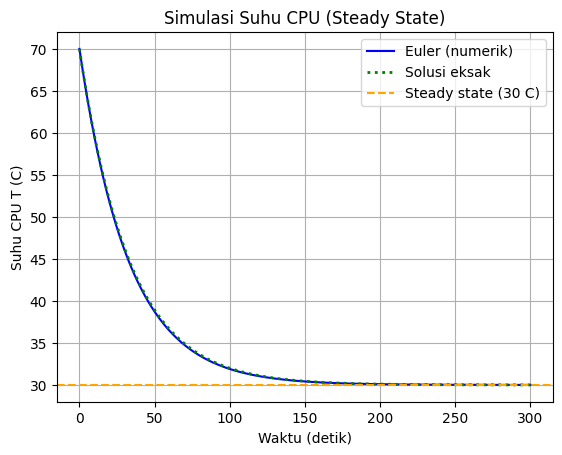

In [3]:
# ===== 4. STEADY STATE (beban 0%, CPU idle) =====
def analytic_cooling(t):
    # solusi eksak, dipakai sebagai pembanding galat Euler
    return T_AMB + (T0 - T_AMB) * np.exp(-K * t)

u0 = np.zeros_like(t)                  # beban CPU 0%
T_num = simulate(t, u0, T0)
T_eks = analytic_cooling(t)
print("Suhu akhir (Euler):", round(T_num[-1], 2), "C")
print("Galat maks Euler vs eksak:", round(np.max(np.abs(T_num - T_eks)), 3), "C")

plt.plot(t, T_num, "b", label="Euler (numerik)")
plt.plot(t, T_eks, "g:", lw=2, label="Solusi eksak")
plt.axhline(T_AMB, color="orange", ls="--", label="Steady state (30 C)")
plt.xlabel("Waktu (detik)")
plt.ylabel("Suhu CPU T (C)")
plt.title("Simulasi Suhu CPU (Steady State)")
plt.legend()
plt.grid(True)
plt.show()

## 5. Respon terhadap sinyal kontrol beban CPU
CPU mulai dari suhu ruangan (30 C), lalu beban diberi sinyal step, impuls, ramp, dan sinusoida.

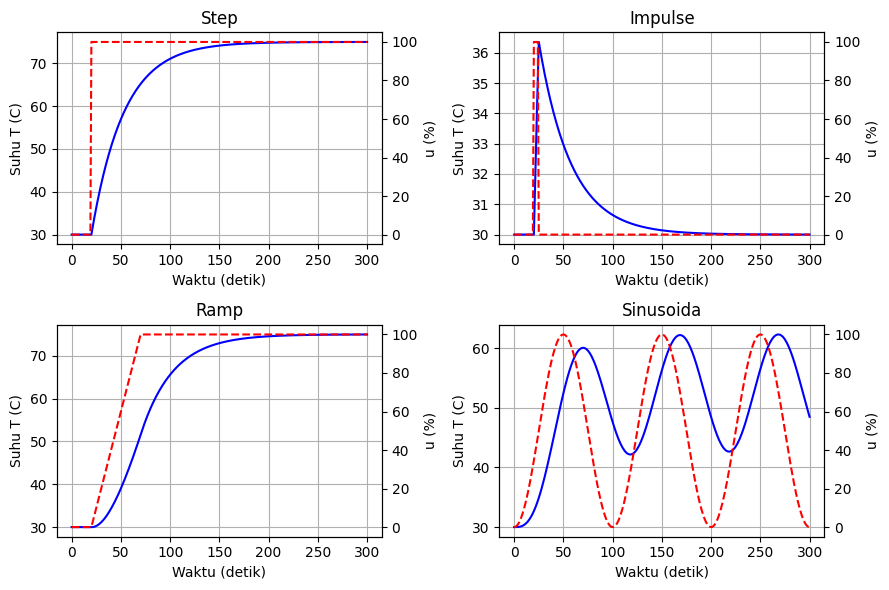

In [4]:
# ===== 5. RESPON TERHADAP SINYAL KONTROL u(t) = BEBAN CPU (%) =====
def sig_step(t):    return np.where(t >= 20, 100.0, 0.0)      # beban naik mendadak, menetap
def sig_impulse(t): return np.where((t >= 20) & (t < 25), 100.0, 0.0)  # pulsa 5 detik
def sig_ramp(t):    return np.clip(2.0 * (t - 20), 0.0, 100.0)  # naik 2 %/detik
def sig_sine(t):    return 50.0 + 50.0 * np.sin(2*np.pi*t/100.0 - np.pi/2)  # periode 100 detik

scenarios = [("Step", sig_step), ("Impulse", sig_impulse),
             ("Ramp", sig_ramp), ("Sinusoida", sig_sine)]

fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, (nama, fungsi) in zip(axes.ravel(), scenarios):
    u = fungsi(t)
    T = simulate(t, u, T_AMB)          # CPU mulai dari suhu ruangan
    ax.plot(t, T, "b")
    ax.set_title(nama)
    ax.set_xlabel("Waktu (detik)")
    ax.set_ylabel("Suhu T (C)")
    ax.grid(True)
    ax2 = ax.twinx()                   # sumbu kanan: beban CPU
    ax2.plot(t, u, "r--")
    ax2.set_ylabel("u (%)")
plt.tight_layout()
plt.show()

## 6. Gangguan: suhu ruangan berubah
Beban 0%, suhu ruangan naik dari 30 C ke 40 C pada t = 100 detik.

Steady state baru (teori): 40.0 C
Suhu akhir gangguan (Euler): 39.98 C


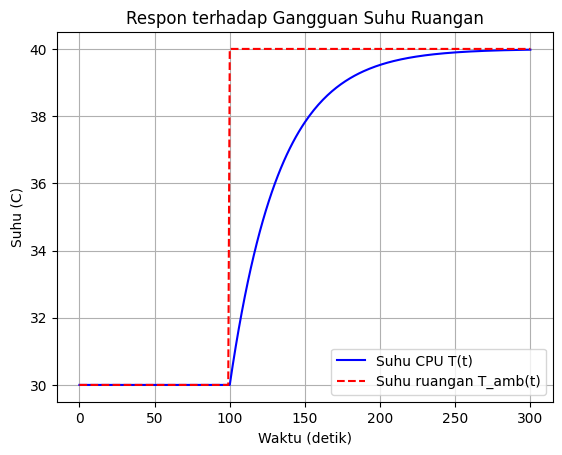

In [5]:
# ===== 6. GANGGUAN: SUHU RUANGAN BERUBAH =====
def amb_disturbance(t):
    # ruangan naik dari 30 C ke 40 C pada t = 100 detik
    return np.where(t >= 100, 40.0, 30.0)

T_amb_d = amb_disturbance(t)
# beban 0%, CPU mulai dari 30 C (setimbang dengan ruangan)
T_dist = simulate(t, np.zeros_like(t), 30.0, T_amb_d)
print("Steady state baru (teori):", 40.0, "C")
print("Suhu akhir gangguan (Euler):", round(T_dist[-1], 2), "C")

plt.plot(t, T_dist, "b", label="Suhu CPU T(t)")
plt.plot(t, T_amb_d, "r--", label="Suhu ruangan T_amb(t)")
plt.xlabel("Waktu (detik)")
plt.ylabel("Suhu (C)")
plt.title("Respon terhadap Gangguan Suhu Ruangan")
plt.legend()
plt.grid(True)
plt.show()